In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import silhouette_score

In [9]:
df=pd.read_csv("/home/backup/ml_datasets/Mall_Customers.csv")
print(df)
print(df.info())
print(df.isnull().sum())

     CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0             1    Male   19                  15                      39
1             2    Male   21                  15                      81
2             3  Female   20                  16                       6
3             4  Female   23                  16                      77
4             5  Female   31                  17                      40
..          ...     ...  ...                 ...                     ...
195         196  Female   35                 120                      79
196         197  Female   45                 126                      28
197         198    Male   32                 126                      74
198         199    Male   32                 137                      18
199         200    Male   30                 137                      83

[200 rows x 5 columns]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 column

In [11]:
x=df[["Age","Annual Income (k$)"]]
print(x.head())

   Age  Annual Income (k$)
0   19                  15
1   21                  15
2   20                  16
3   23                  16
4   31                  17


In [12]:
scaler=StandardScaler()
x_scaled=scaler.fit_transform(x)

In [14]:
#K Means
k_means=KMeans(n_clusters=5,random_state=42,n_init=10)
k_pred=k_means.fit_predict(x_scaled)
k_sil=silhouette_score(x_scaled,k_pred)

In [17]:
#Agglomerative
aggl_model=AgglomerativeClustering(n_clusters=5,linkage="ward")
aggl_pred=aggl_model.fit_predict(x_scaled)
aggl_sil=silhouette_score(x_scaled,aggl_pred)

In [24]:
print("Silhouette Score\n")
print("K Means Clustering : ",round(k_sil,3))
print("Agglomerative Clustering : ",round(aggl_sil,3))

Silhouette Score

K Means Clustering :  0.393
Agglomerative Clustering :  0.358


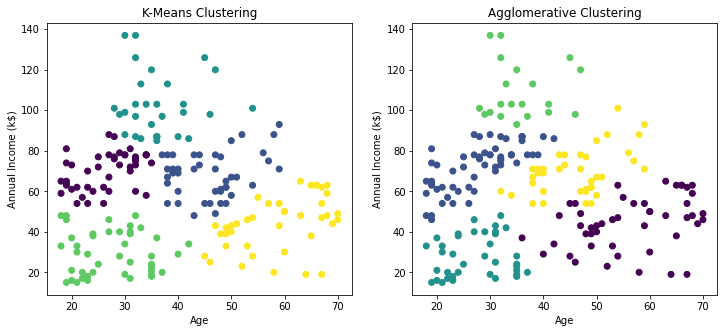

In [27]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.scatter(x["Age"],
            x["Annual Income (k$)"],
            c=k_pred,
            cmap="viridis"
           )
plt.title("K-Means Clustering")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
plt.subplot(1,2,2)
plt.scatter(x["Age"],
            x["Annual Income (k$)"],
            c=aggl_pred,
            cmap="viridis"
           )
plt.title("Agglomerative Clustering")
plt.xlabel("Age")
plt.ylabel("Annual Income (k$)")
plt.show()